In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# suppress warnings
import warnings
warnings.simplefilter('ignore')

### Load data

In [67]:
import re 

# define time resolution
timeres = '1H'
## calculate period based on 1 day
number = int(re.sub(r'\D', '', timeres)) # \D matches any non-digit character

# Read in TSD and rates data _{timeres}
tsd_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/all_seaflow_tsd_mixed_v1_all_{timeres}.pickle'
rates_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/final_rates_v1_all_{timeres}.pickle'

all_tsd = pd.read_pickle(tsd_path)
final_rates = pd.read_pickle(rates_path)
# only get good tsd dimensions
good_tsd = final_rates[['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']].merge(all_tsd, how = 'left')

### Plot diel cycle

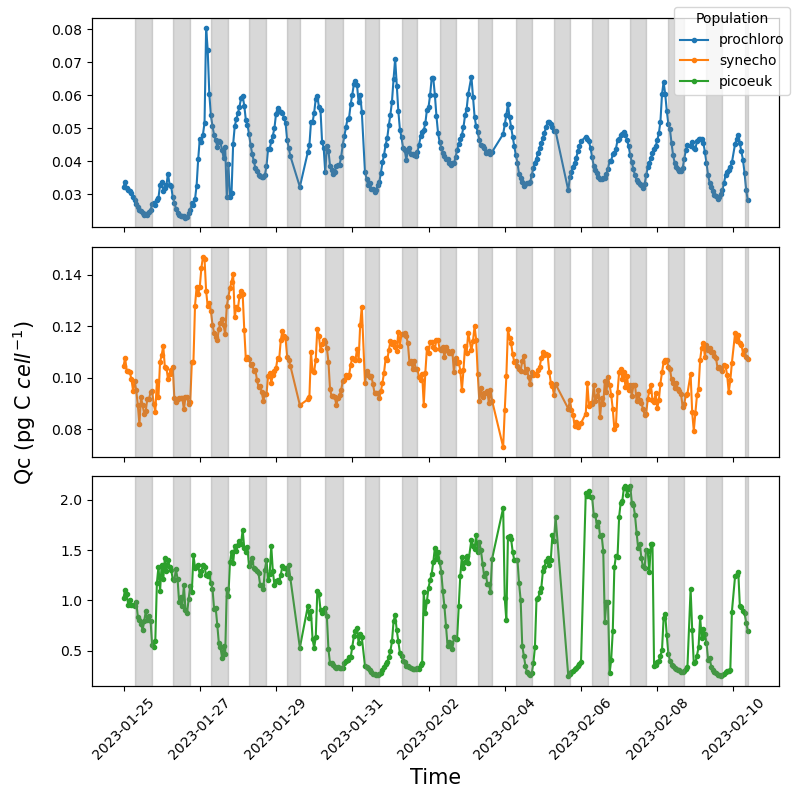

In [68]:
import matplotlib.ticker as ticker

hourly_sfl = pd.read_pickle('/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/hourly_sf_v1_all.pickle')
# only plot the one cruise
diel_cruise = hourly_sfl.loc[hourly_sfl['cruise'] == 'TN412']
pops = ['prochloro', 'synecho', 'picoeuk']
colors = ['tab:blue', 'tab:orange', 'tab:green']
ax_count = 0

# make plots
fig, axs = plt.subplots(figsize = (8, 8), nrows = 3, sharex = True)
for pop, c in zip(pops, colors):
    # subset by pop and time
    pop_df = diel_cruise.loc[(diel_cruise['pop'] == pop) & 
                             (diel_cruise['time'] >= '2023-01-25 00:00:00+00:00') & 
                             (diel_cruise['time'] < '2023-02-10 10:00:00+00:00')]
    l = axs[ax_count].plot(pop_df['time'], pop_df['Qc_hour'], marker = '.', c = c,
                       label = pop)
    # show day/night
    twinax=axs[ax_count].twinx()
    twinax.fill_between(pop_df['time'], 0, 1, where=pop_df['night']=='night',color='gray',
                        alpha=0.3, transform=axs[ax_count].get_xaxis_transform())
    # hide y ticks
    twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                        right=False, labelright=False, bottom=False, labelbottom=False)
    ax_count += 1

## aesthetics
# make x tick labels angled
axs[ax_count-1].tick_params(axis='x', rotation=45)
# set tick frequency
axs[ax_count-1].xaxis.set_major_locator(ticker.MultipleLocator(2))
## legend
handles, labels = [], []
# Loop through all axes in the 2D array
for ax in axs.flatten():
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)
# Create a single legend for the entire figure
fig.legend(handles, labels, title='Population')

# labels
axs[ax_count-1].set_xlabel('Time', fontsize = 15)
fig.supylabel("Qc (pg C $cell^{-1}$)", fontsize = 15)
# axs[ax_count-1].set_xlabel('Time')
plt.tight_layout()


### Plot diel components figure

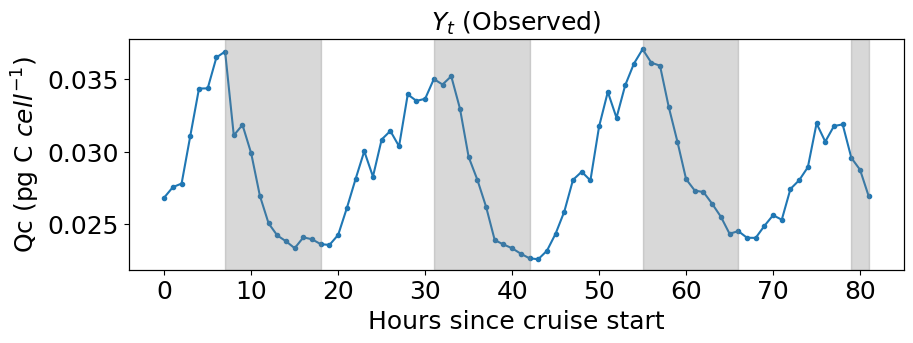

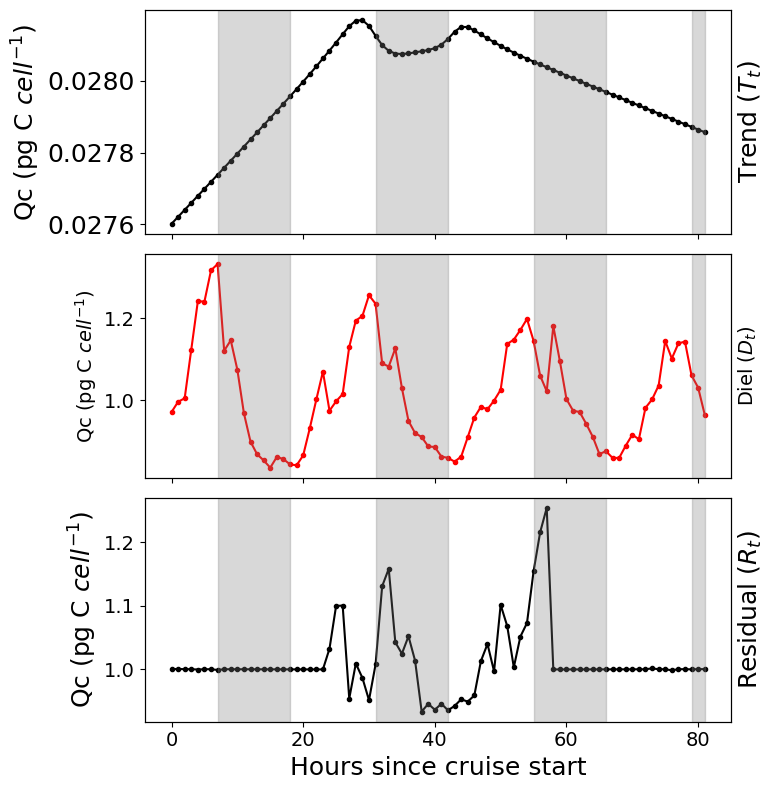

In [69]:
plt.style.use('default')

## make a plot
g1_pro = all_tsd.loc[(all_tsd['pop'] == 'prochloro') & 
                  (all_tsd['cruise'] == 'KM1602') &
                  (all_tsd['model'] == 'STL')].sort_values(by='time').reset_index(drop=True)
# plot each component
g1_pro['hour'] = np.arange(0, len(g1_pro))
x = g1_pro['hour']
yt = g1_pro['data_with_missing']
tt = g1_pro['trend']
dt = g1_pro['diel']
rt = g1_pro['resid']

# make plots
fig, axs = plt.subplots(figsize = (10, 3))
axs.plot(x, yt, marker = '.', c = 'tab:blue')
# show day/night
twinax=axs.twinx()
twinax.fill_between(x, 0, 1, where=g1_pro['time_of_day']=='night',color='gray',
                    alpha=0.3, transform=axs.get_xaxis_transform())
# hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                    right=False, labelright=False, bottom=False, labelbottom=False)

axs.set_xlabel('Hours since cruise start', fontsize = 18)
axs.set_ylabel('Qc (pg C $cell^{-1}$)', fontsize = 18)
axs.set_title('$Y_t$ (Observed)', fontsize = 18)
axs.tick_params(axis='both', labelsize=18)
plt.show()

## make components plot
fig, axs = plt.subplots(figsize = (8, 8), nrows = 3, sharex = True)
### trend component
axs[0].plot(x, tt, marker = '.', c = 'k')
# show day/night
twinax=axs[0].twinx()
twinax.fill_between(x, 0, 1, where=g1_pro['time_of_day']=='night',color='gray',
                    alpha=0.3, transform=axs[0].get_xaxis_transform())
# hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                    right=False, labelright=False, bottom=False, labelbottom=False)
twinax.set_ylabel('Trend ($T_t$)', fontsize = 18)
axs[0].set_ylabel('Qc (pg C $cell^{-1}$)', fontsize = 18)
axs[0].tick_params(axis='both', labelsize=18)

### diel component
axs[1].plot(x, dt, marker = '.', c = 'r')
# show day/night
twinax=axs[1].twinx()
twinax.fill_between(x, 0, 1, where=g1_pro['time_of_day']=='night',color='gray',
                    alpha=0.3, transform=axs[1].get_xaxis_transform())
# hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                    right=False, labelright=False, bottom=False, labelbottom=False)
twinax.set_ylabel('Diel ($D_t$)', fontsize = 14)
axs[1].set_ylabel('Qc (pg C $cell^{-1}$)', fontsize = 14)
axs[1].tick_params(axis='both', labelsize=14)

### residual component
axs[2].plot(x, rt, marker = '.', c = 'k')
# show day/night
twinax=axs[2].twinx()
twinax.fill_between(x, 0, 1, where=g1_pro['time_of_day']=='night',color='gray',
                    alpha=0.3, transform=axs[2].get_xaxis_transform())
# hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                    right=False, labelright=False, bottom=False, labelbottom=False)
twinax.set_ylabel('Residual ($R_t$)', fontsize = 18)
axs[2].set_ylabel('Qc (pg C $cell^{-1}$)', fontsize = 18)
axs[2].set_xlabel('Hours since cruise start', fontsize = 18)
axs[2].tick_params(axis='both', labelsize=14)
for ax in axs.flat:
    ax.grid(False)
plt.tight_layout()


# axs.set_ylabel('Qc (pg C $cell^{-1}$)', fontsize = 14)
# axs.set_title('$Y_t$ (Observed)', fontsize = 15)
# axs.tick_params(axis='both', labelsize=14)
# plt.show()

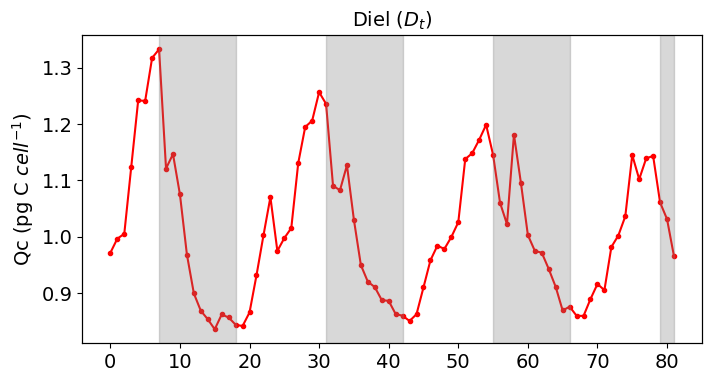

In [70]:
## only plot the diel component
fig, axs = plt.subplots(figsize = (8, 4))
### diel component
axs.plot(x, dt, marker = '.', c = 'r')
# show day/night
twinax=axs.twinx()
twinax.fill_between(x, 0, 1, where=g1_pro['time_of_day']=='night',color='gray',
                    alpha=0.3, transform=axs.get_xaxis_transform())
# hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                    right=False, labelright=False, bottom=False, labelbottom=False)
axs.set_title('Diel ($D_t$)', fontsize = 14)
axs.set_ylabel('Qc (pg C $cell^{-1}$)', fontsize = 14)
axs.tick_params(axis='both', labelsize=14)


### Plot gradients PP only

Text(0.5, 0, 'Hours Since Cruise Start')

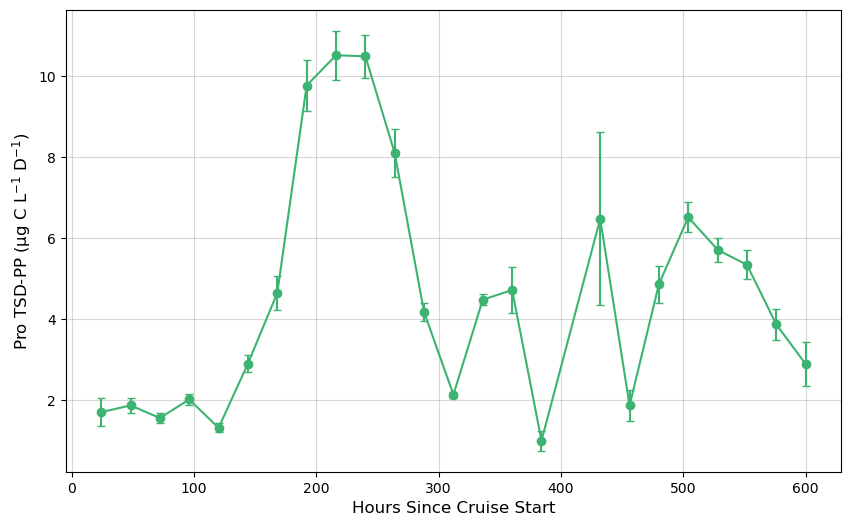

In [72]:
fig, axs = plt.subplots(figsize = (10, 6))
g_cruise_name = 'TN397'
## plot rates data
g_cruise_rates = final_rates.loc[(final_rates['cruise']==g_cruise_name)&(final_rates['pop']=='prochloro')]
# calculate hour and subset
g_cruise_rates['hour'] = g_cruise_rates['cruise_day']*24
# offset hours
g_cruise_rates['hour']-12
x = g_cruise_rates['hour']
y = g_cruise_rates['productivity']
yerr = g_cruise_rates['productivity_se']
# plot productivity + error bars (se)
axs.errorbar(x, y, yerr=yerr, capsize=3, ecolor = "mediumseagreen", color = "mediumseagreen", fmt='o', linestyle = '-')
# add grid
axs.grid(alpha=0.5)
axs.set_ylabel('Pro TSD-PP (µg C $\mathregular{{L^{{-1}}}}$ $\mathregular{{D^{{-1}}}}$)', fontsize=12)
axs.set_xlabel('Hours Since Cruise Start', fontsize=12)

### Make G4-5 plots for Patrick

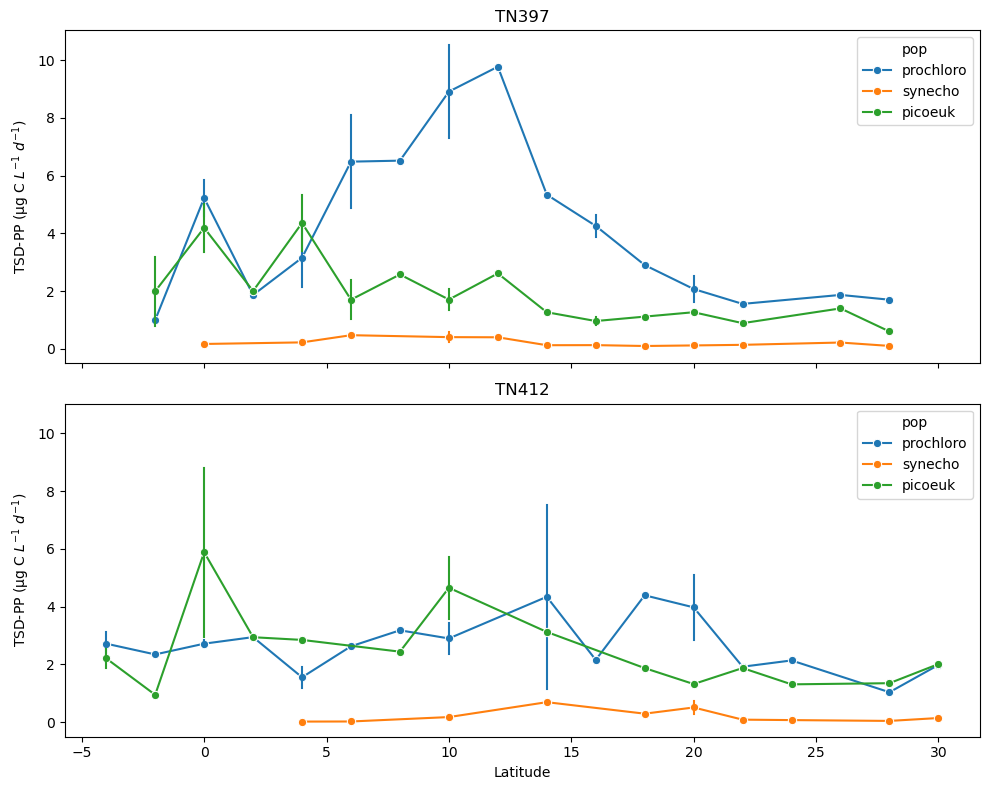

In [90]:
fig, axs = plt.subplots(figsize = (10, 8), nrows = 2, sharex = True, sharey = True)
cruise_names = ['TN397', 'TN412']
colors = ['tab:blue', 'tab:orange', 'tab:green']
ax_count = 0
# loop through each poulation
for g_cruise_name in cruise_names:
    ## plot rates data
    g_cruise_rates = final_rates.loc[(final_rates['cruise']==g_cruise_name)]
    # round by 2º latitude
    g_cruise_rates['round_lat'] = np.round(g_cruise_rates['lat'] / 2) * 2
    sns.lineplot(g_cruise_rates, x = 'round_lat', y = 'productivity', 
                 hue = 'pop', ax = axs[ax_count], marker='o', errorbar='se', err_style='bars')
    axs[ax_count].set_title(g_cruise_name)
    axs[ax_count].set_ylabel('TSD-PP (µg C $L^{-1}$ $d^{-1}$)')
    ax_count += 1

axs[ax_count-1].set_xlabel('Latitude')
plt.tight_layout()

In [95]:
## save data
g45 = final_rates.loc[final_rates['cruise'].isin(cruise_names)]
# subset
g45.drop(columns = ['pval', 'ALOHA', 'model', 'rmse']).to_csv('~/Downloads/patrick_g45_tsd-PP.csv', 
                                                              index = False)

#### KM1513 MLD

In [ ]:
import gsw
import pycmap

# pull KM1513 bottle data
api = pycmap.API(token='ec600c40-bb53-11ec-9220-c1bedea45ab3')
tbl_name = 'tblHOE_legacy_2A'
bottle_df = api.get_dataset(tbl_name)

# ctd: DataFrame with columns
# Salinity (PSS-78), Pressure (dbar)– sub this for depth, Temperature (deg C), lon, lat, Station, Cast, depth
mld = bottle_df.copy()

# Convert Practical Salinity to Absolute Salinity (g/kg)
mld["SA"] = gsw.SA_from_SP(
    SP=mld["CTD_Salinity"].values,
    p=mld["depth"].values,
    lon=mld["lon"].values,
    lat=mld["lat"].values,
)
# Potential temperature (ref pressure = 0 dbar)
mld["pt"] = gsw.pt0_from_t(
    SA=mld["SA"].values,
    t=mld["CTD_Temperature"].values,
    p=mld["depth"].values,
)
# Conservative Temperature
mld["CT"] = gsw.CT_from_t(
    SA=mld["SA"].values,
    t=mld["CTD_Temperature"].values,
    p=mld["depth"].values,
)
# Potential density anomaly referenced to 0 dbar (sigma0, kg/m^3 - 1000)
mld["sigma0"] = gsw.sigma0(
    SA=mld["SA"].values,
    CT=mld["CT"].values,
)
# Potential density (kg/m^3)
mld["PD"] = mld["sigma0"] + 1000.0

## make plot of potential density across station and depth
# format data into 2D matrix
df = mld.copy()
df['round_depth'] = df['depth'].round()
df = df.sort_values(["Station", "round_depth"])

# only include stations with at least a maximum depth of 100m
max_depths = df.groupby(['Station'])['round_depth'].max().reset_index()
deep_stations = max_depths.loc[max_depths['round_depth'] > 100, 'Station'].values
df = df.loc[df['Station'].isin(deep_stations)]

#### for each station, find the closest pressure or depth to 10 dbar or m
target_depth = 10.0
# For each Station–Cast group, find the index of the row with depth closest to 10 m
idx_closest = (
    df
    .groupby(["Station", "Cast"], group_keys=False)
    .apply(lambda g: g.iloc[(g["depth"] - target_depth).abs().argmin()])
)
# idx_closest is already a DataFrame of the selected rows; we can keep just what we want
ref_df = idx_closest[["Station", "Cast", "Potential_Density"]].reset_index(drop=True)
ref_df.rename(columns = {"Potential_Density": "ref_PD"}, inplace = True)

# Left join on Station, Cast, lat, lon
sub_df = df.merge(
    ref_df,
    how="left",
)

# Now apply the density difference criterion:
# filter(PD.x > PD.y + 0.03), group_by(Station, Cast), arrange(depth), select(depth), slice(1)
mld_mixed = (
    sub_df[sub_df["Potential_Density"] > sub_df["ref_PD"] + 0.03]
    .sort_values(["Station", "Cast", "depth"])
    .groupby(["Station", "Cast"], as_index=False)
    .first()[["Station", "Cast", "depth"]]
)
# mld_mixed now holds the mixed layer depth (first depth where density exceeds ref + 0.03 kg/m^3)

#### plot nitracline

In [ ]:
nitrogen = df['NO3_NO2']

# plot depth of nitracline at each station
ax = sns.scatterplot(df, x = 'NO3_NO2', y = 'depth', hue = 'Station')
ax.invert_yaxis()

#### plot calculated MLD

In [ ]:
# Build a pivot table: rows = depth, columns = Station, values = Potential_Density
piv = df.pivot_table(index="round_depth",
                     columns="Station",
                     values="Potential_Density",
                     aggfunc=np.mean)

# Plot heatmap
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(piv.values,
               aspect="auto",
               cmap="viridis",
               interpolation="nearest")

# Axis labels and ticks
ax.set_xlabel("Station")
ax.set_ylabel("Depth (m)")

# Map pixel indices back to actual Station and depth values
ax.set_xticks(np.arange(len(piv.columns)))
ax.set_xticklabels(piv.columns, rotation=90)

ax.set_yticks(np.arange(len(piv.index)))
ax.set_yticklabels(piv.index)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Potential Density (kg m$^{-3}$)")

plt.tight_layout()
plt.show()

#### Example time series for presentations/papers

In [ ]:
clean_growth = pd.read_csv('../data/clean_growth_1H.csv')
test_df = clean_growth.loc[(clean_growth['cruise'] == 'KM1513') & 
                           (clean_growth['pop'] == 'prochloro') & 
                           (clean_growth['cruise_day'] == 6) & 
                           (clean_growth['day_half'] == 'first')]

In [ ]:
# plot growth over time
time = test_df['hour'].values          
P = test_df['slope'].values  

plt.scatter(time, P, label='data', c = 'seagreen')
# plt.plot(time, P, c = 'k', linestyle = '--', label='Platt fit')
plt.xlabel('Hours After Dawn')
plt.ylabel('Growth rate ($hour^{-1}$)', fontsize = 14)
# plt.legend()

In [ ]:
## plot diel over time
test_diel_df = hot_cruise.loc[(hot_cruise['cruise'] == 'KM1513') & 
                           (hot_cruise['pop'] == 'prochloro') & 
                           (hot_cruise['cruise_day'] == 10)]
# plot growth over time
time = test_diel_df['day_hour'].values          
P = test_diel_df['diel'].values  

fig, axs = plt.subplots()
axs.scatter(time, P, label='data', c = 'tab:red')
axs.set_xlabel('Hours After Dawn')
axs.set_ylabel('Diel Component (pg C $cell^{-1}$)', fontsize = 14)
# plot day/night shading
twinax = axs.twinx()
twinax.fill_between(time, 0, 1, where=test_diel_df['time_of_day']=='night',color='gray',
                    alpha=0.3, transform=axs.get_xaxis_transform())
# hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                    right=False, labelright=False, bottom=False, labelbottom=False)